# PHASE: W9-B

**SCIENTIFIC QUESTION:** How many coherent post-draft evidence units are useful?

**PREREQUISITES:** Complete FIT-frozen upstream phases; see runbook.

**INPUT ARTIFACTS:** configs/week9/w9b.yaml; exact paths in its data block and upstream frozen manifests.

**EXPECTED OUTPUTS:** phase JSONL cache, identity sidecar, report, summary CSV and run manifest. No synthetic fallbacks.

**CURRENT SPLIT:** FIT (default). INTERNAL-VAL is confirmation and has been inspected. DEV has been inspected. TEST has no notebook control.

**FULL RUN FLAG:** `RUN_FULL=False`. Full and smoke execution have separate explicit flags; Run All performs analysis only when real artifacts exist.


In [1]:
from pathlib import Path
import sys, json, subprocess
import pandas as pd
from IPython.display import display
ROOT = Path.cwd().resolve()
while not (ROOT / 'src/week9').is_dir():
    if ROOT == ROOT.parent:
        raise FileNotFoundError('Open this notebook within CS787-RAG-Project')
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.week9.config import load_config, load_frozen
from src.week9.runner import rows_path, phase_dir, load_phase
RUN_FULL = True
RUN_SMOKE = False
FREEZE_FIT = False
SMOKE_LIMIT = 2
SPLIT = 'fit'
assert SPLIT in ('fit', 'internal_val', 'dev')
PHASE = 'b'
CONFIG = ROOT / 'configs/week9/w9b.yaml'
SCRIPT = ROOT / 'scripts/week9/run_w9b_ke_surface.py'
cfg = load_config(CONFIG)


In [2]:
command = [str(ROOT / 'sara_env/bin/python'), str(SCRIPT), '--split', SPLIT,
           '--config', str(CONFIG), '--resume']
if RUN_FULL:
    if FREEZE_FIT:
        assert SPLIT == 'fit'
        command.append('--freeze')
    if PHASE == 'g':
        command.append('--collect-headroom-oof')
    subprocess.run(command, cwd=ROOT, check=True)
else:
    print('Full experiment disabled. Set RUN_FULL=True explicitly.')
if RUN_SMOKE:
    subprocess.run(command + ['--smoke-limit', str(SMOKE_LIMIT)], cwd=ROOT, check=True)


`torch_dtype` is deprecated! Use `dtype` instead!
Loading checkpoint shards: 100%|██████████| 3/3 [00:01<00:00,  2.32it/s]
Some weights of XMistralForCausalLM were not initialized from the model checkpoint at mistralai/Mistral-7B-Instruct-v0.2 and are newly initialized: ['projector.projector.0.bias', 'projector.projector.0.weight', 'projector.projector.2.bias', 'projector.projector.2.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
The new embeddings will be initialized from a multivariate normal distribution that has old embeddings' mean and covariance. As described in this article: https://nlp.stanford.edu/~johnhew/vocab-expansion.html. To disable this, use `mean_resizing=False`
The new lm_head weights will be initialized from a multivariate normal distribution that has old embeddings' mean and covariance. As described in this article: https://nlp.stanford.edu/~johnhew/vocab-expansion.html. To disable this, use `m

W9-B: 6984 saved real rows; complete=True; artifacts=/home/gunavenkat/Downloads/CS787-RAG-Project/results/week9/ke_surface/fit


In [3]:
directory = phase_dir(cfg, PHASE, SPLIT)
path = rows_path(cfg, PHASE, SPLIT)
if path.is_file():
    rows = load_phase(cfg, PHASE, SPLIT)
    run_manifest = json.loads((directory / f'w9{PHASE}_manifest.json').read_text())
    from src.week9.provenance import digest
    expected_config = dict(cfg, _seed=run_manifest['seed'])
    if digest(expected_config) != run_manifest['config_hash']:
        raise ValueError('Notebook configuration differs from the saved run')
    print('Complete:', run_manifest['complete'], 'Rows:', len(rows))
    print('Input/source fingerprints validated by load_phase.')
    frame = pd.DataFrame(rows)
    display(frame[[c for c in ['question_id','paper_id','policy','representation','retriever',
        'retrieval_width','evidence_k','f1','total_query_prompt_tokens'] if c in frame]].head(12))
    for table in sorted(directory.glob('*.csv')):
        print(table.name)
        display(pd.read_csv(table).head(30))
else:
    print('No full-run artifacts yet. Run the phase manually; no fallback metrics were created.')


Complete: True Rows: 6984
Input/source fingerprints validated by load_phase.


,question_id,paper_id,policy,retrieval_width,evidence_k,f1,total_query_prompt_tokens
0,512,139,K_E=0,20,0,0.800000,937
1,512,139,K_E=1,20,1,0.705882,3059
2,512,139,K_E=2,20,2,0.705882,4110
3,512,139,K_E=4,20,4,0.705882,6346
4,513,139,K_E=0,20,0,1.000000,794
5,513,139,K_E=1,20,1,0.500000,2739
6,513,139,K_E=2,20,2,0.500000,3884
7,513,139,K_E=4,20,4,0.500000,6060
8,745,207,K_E=0,20,0,0.111111,977
9,745,207,K_E=1,20,1,0.000000,2583


w9b_query_matrix.csv


,question_id,paper_id,oracle_evidence_k,epsilon_oracle_evidence_k,f1_evidence_k_0,f1_evidence_k_1,f1_evidence_k_2,f1_evidence_k_4
0,10,1,0,0,0.181818,0.044444,0.142857,0.046512
1,100,26,1,1,0.000000,1.000000,1.000000,1.000000
2,1006,295,1,1,0.000000,0.705882,0.318182,0.341463
3,1007,295,0,0,1.000000,1.000000,1.000000,0.000000
4,101,26,1,1,0.000000,0.076923,0.076923,0.076923
5,1012,297,2,2,0.160000,0.000000,0.190476,0.190476
6,1014,299,1,1,0.000000,0.266667,0.266667,0.133333
7,1015,299,0,0,0.000000,0.000000,0.000000,0.000000
8,1016,300,0,0,1.000000,1.000000,0.303030,0.303030
9,1017,300,0,0,1.000000,1.000000,1.000000,1.000000


w9b_summary.csv


,policy,n_queries,f1,mean_selected_delta_f1,help_selected_rate,hurt_selected_rate,exact_match,help,hurt,answer_changed,...,num_lm_calls,retrieval_query_time,selection_latency,extraction_latency,revision_latency,measured_end_to_end_latency,extraction_rate,promotion_rate,faithfulness,complexity
0,K_E=0,1746,0.385631,0.000000,NaN,NaN,0.227950,0.000000,0.000000,0.000000,...,1.0,0.00496,8.629655e-07,NaN,NaN,NaN,0.0,0.0,NaN,0
1,K_E=1,1746,0.380967,-0.004664,0.286369,0.249141,0.201031,0.286369,0.249141,0.710195,...,2.0,0.00496,2.962398e-01,NaN,1.826296,NaN,0.0,1.0,1.0,1
2,K_E=2,1746,0.385004,-0.000627,0.321306,0.281787,0.193013,0.321306,0.281787,0.762887,...,2.0,0.00496,2.969836e-01,NaN,2.270500,NaN,0.0,1.0,1.0,2
3,K_E=4,1746,0.380388,-0.005243,0.357388,0.302978,0.176976,0.357388,0.302978,0.805269,...,2.0,0.00496,2.964965e-01,NaN,3.057159,NaN,0.0,1.0,1.0,3


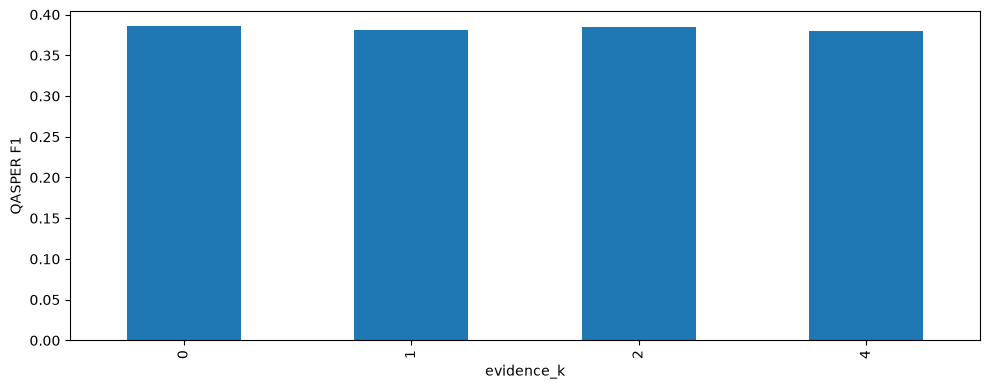

In [4]:
if path.is_file():
    import matplotlib.pyplot as plt
    if PHASE == 'a':
        table = pd.read_csv(directory / 'w9a_summary.csv')
        display(table.pivot_table(index=['representation','retriever'], columns='retrieval_width',
                                 values='all_gold_evidence_recall'))
        ax = table.pivot_table(index='representation', columns='retriever',
                              values='all_gold_evidence_recall').plot.bar(figsize=(12,5))
        ax.set_ylabel('All annotated evidence recall (paragraph proxy)')
    elif 'f1' in frame:
        group = 'evidence_k' if PHASE == 'b' else 'policy'
        ax = frame.groupby(group).f1.mean().plot.bar(figsize=(10,4))
        ax.set_ylabel('QASPER F1')
    else:
        ax = None
    if ax is not None:
        (directory / 'figures').mkdir(exist_ok=True)
        ax.figure.tight_layout()
        ax.figure.savefig(directory / 'figures' / f'w9{PHASE}_overview.png', dpi=160)
        plt.show()


## Evidence-count oracles and available-pool check

A is now frozen to the existing FIT selection-rule winner: **FIXED-5 / SEMANTIC @20**. See `results/week9/retrieval/fit/freeze_audit/W9A_FREEZE_AUDIT.md`.

Hold **DraftSemantic** fixed and evaluate **K_E = 0, 1, 2, 4**. K=0 reuses the saved initial draft; other budgets use raw chunks here, with extraction studied later in D/E. A unit has median 1,022 tokens in this representation. About 14.7% of FIT queries have fewer than four candidates, so nominal K is a cap and can differ from the actual count.

The exact oracle chooses the smallest K tied for maximum F1. The epsilon oracle chooses the smallest K within **0.01 F1** of that maximum. Report both over all queries and over the subgroup with at least four available candidates. These are retrospective ceilings, not trained predictors. A large mass at K=2/4 motivates G's headroom audit but does not automatically pass G's separate gate.


In [5]:
if path.is_file() and 'frame' in globals() and run_manifest.get('complete'):
    from src.week9.ke_surface import surface_analysis
    query_matrix, oracle_summary = surface_analysis(rows, counts=(0,1,2,4), epsilon=.01)
    display(pd.DataFrame(oracle_summary['fixed_evidence_k']))
    display(query_matrix.head())
    full_pool_ids = set(frame.loc[frame.evidence_k.eq(4) & frame.retrieval_actual_count.ge(4), 'question_id'].astype(str))
    pool_report = frame.groupby(['evidence_k','evidence_actual_count']).size().rename('queries').reset_index()
    print('Requested vs actual evidence counts:')
    display(pool_report)
    distributions = []
    for population, mask in [('all queries', pd.Series(True, index=query_matrix.index)),
                             ('at least four available candidates', query_matrix.question_id.astype(str).isin(full_pool_ids))]:
        subset = query_matrix.loc[mask]
        for oracle in ['oracle_evidence_k','epsilon_oracle_evidence_k']:
            counts = subset[oracle].value_counts().reindex([0,1,2,4], fill_value=0)
            for k, count in counts.items():
                distributions.append(dict(population=population, oracle=oracle, evidence_k=int(k),
                    count=int(count), queries=len(subset), rate=float(count/len(subset)) if len(subset) else None))
    oracle_distribution = pd.DataFrame(distributions)
    print('Exact and epsilon=.01 oracle distributions:')
    display(oracle_distribution)
    pool_report.to_csv(directory/'w9b_requested_vs_actual_counts.csv', index=False)
    oracle_distribution.to_csv(directory/'w9b_oracles_by_pool_coverage.csv', index=False)
else:
    print('Oracle analysis awaits a complete saved W9-B surface; no model run is launched here.')


,evidence_k,f1,final_prompt_tokens,total_query_prompt_tokens,total_query_generated_tokens,help,hurt
0,0,0.385631,940.544101,940.544101,16.654639,0.000000,0.000000
1,1,0.380967,2026.348225,2966.892325,54.152921,0.286369,0.249141
2,2,0.385004,3041.357961,3981.902062,56.474800,0.321306,0.281787
3,4,0.380388,4866.666094,5807.210195,58.343643,0.357388,0.302978


,question_id,paper_id,oracle_evidence_k,epsilon_oracle_evidence_k,f1_evidence_k_0,f1_evidence_k_1,f1_evidence_k_2,f1_evidence_k_4
0,10,1,0,0,0.181818,0.044444,0.142857,0.046512
1,100,26,1,1,0.000000,1.000000,1.000000,1.000000
2,1006,295,1,1,0.000000,0.705882,0.318182,0.341463
3,1007,295,0,0,1.000000,1.000000,1.000000,0.000000
4,101,26,1,1,0.000000,0.076923,0.076923,0.076923


Requested vs actual evidence counts:


,evidence_k,evidence_actual_count,queries
0,0,0,1746
1,1,1,1746
2,2,1,5
3,2,2,1741
4,4,1,5
5,4,2,62
6,4,3,189
7,4,4,1490


Exact and epsilon=.01 oracle distributions:


,population,oracle,evidence_k,count,queries,rate
0,all queries,oracle_evidence_k,0,956,1746,0.547537
1,all queries,oracle_evidence_k,1,323,1746,0.184994
2,all queries,oracle_evidence_k,2,211,1746,0.120848
3,all queries,oracle_evidence_k,4,256,1746,0.146621
4,all queries,epsilon_oracle_evidence_k,0,965,1746,0.552692
5,all queries,epsilon_oracle_evidence_k,1,330,1746,0.189003
6,all queries,epsilon_oracle_evidence_k,2,206,1746,0.117984
7,all queries,epsilon_oracle_evidence_k,4,245,1746,0.140321
8,at least four available candidates,oracle_evidence_k,0,803,1490,0.538926
9,at least four available candidates,oracle_evidence_k,1,271,1490,0.181879


## Manual decision checkpoint

Inspect completeness, source/config fingerprints, paired paper-bootstrap intervals and total query-time token costs before freezing. A smoke run cannot freeze a configuration. Summary tables come only from saved real rows. Exact-span support is separate from fact entailment, which is unmeasured unless explicitly judged. No next phase is launched here.

To regenerate summaries without loading the generator, run this phase script with `--analyze-only --resume`. Add `--freeze` only after a complete FIT run. H requires verified outer paper-fold outcomes and `--collect-oof`; see the runbook. Changes to source/config/model fingerprints require a new output root; incompatible caches are refused.
